# Figure 4 Supplement 1: Reward Rate vs. Bound (PD task)

PD-task analog of `Figure04_RRvsBound.ipynb`

## What this notebook does

Shows how participants' decision bounds relate to their reward rate across three
blocks in the predefined-bound (PD) task, and how bounds adapt during the first 40
trials of each block -- the same analyses as `Figure04_RRvsBound.ipynb`, applied to
PD instead of OL. In PD, the subject chooses the bound before each trial starts
(hence "predefined"), so the bound is known exactly rather than estimated from step
positions -- see `get_data_table`'s `task_type='PD'` handling in `pigeon/data.py`
for how this simplifies the data pipeline (no NDT estimation, no bias correction).

**Formatted figure (2 rows x 3 columns)**:
- **Top row** (one panel per block): Scatter of mean bound (x) vs. reward rate (y)
  per subject, with a simulation ribbon (5th-95th percentile from 1000 simulated
  subjects per bound with a fixed bound, the optimal policy). A light blue band marks the
  near-optimal bounds (median simulated RR >= 95% of its maximum); black dashed crosshairs
  mark the participant median. Same conventions as `Figure04_RRvsBound.ipynb`. Error bars:
  SD of the bound the subject set across trials.
- **Bottom row** (one panel per block): Within-block z-scored bound adaptation curve
  (mean +/- SEM ribbon) with permutation null band, plus a small tau inset in the
  lower-right corner.

**Bound comparison across blocks** (standalone, not in final figure): scatter of
mean bound in block 1 vs. block 2 and block 2 vs. block 3.

**Data**: PD task, all three blocks, lowest SNR condition (SNR index 0).

**PD-specific notes**:
- PD's step budget is 800 steps/block, not OL's 600 -- see `BLOCK_DEFAULTS_PD` in
  `pigeon/simulation.py` (verified against the raw PD CSVs' `tc_steps_max` field,
  constant across all 60 subjects).
- `coin_count` is occasionally NaN on the very last trial of a block (a PsychoPy
  logging quirk where a block-end bonus message overwrites that cell -- see
  `get_data_table`). The reward-rate calculation below takes the last *non-NaN*
  `coin_count` per subject/block/SNR, so in the rare case this affects the true
  final trial, the reward total is off by at most one trial's coins out of ~20-50
  trials per block -- a negligible approximation, not a bug.

## Imports

Imports standard scientific Python libraries and pigeon analysis functions. No data loading or filtering.

## Load data

Loads all PD (predefined-bound) trials via `get_data_table(task_type='PD')`. This reads all subject CSV files and marks wall hits; DT = RT (no NDT to subtract) and bias correction is skipped automatically for PD (see `pigeon/data.py`).

## Compute bound and coin summaries

**`get_bound_summary`** (via `get_good_trial_array` internally):
- **Data included**: `DT >= 2`, `trial_number >= 10`, `bound` finite and non-zero, `correct >= 0`, `wall_hit = False`, `rt_below_cutoff = False`
- **Data excluded**: Short DT trials, warm-up trials, wall-hit trials, missing bounds
- Output: mean and std of |bound| per (subject, block, SNR) using `max_rt='all'` (no per-DT binning)

**Coin summary** (computed inline):
- For each (subject, block, SNR), takes the last `coin_count` value (cumulative total at end of block)
- Reward rate = total coins / 800 steps per block (PD's step budget, see `BLOCK_DEFAULTS_PD`)
- **Data included**: All trials sorted by trial number; last coin_count value per group
- **Data excluded**: Subjects/blocks/SNRs with no valid trials

In [1]:
import sys
sys.path.insert(0, '..')

import numpy as np
import matplotlib.pyplot as plt
import scipy.stats

from pigeon.data import get_data_table
from pigeon.data import get_bound_summary
from pigeon.simulation import get_simulated_data_table, BLOCK_DEFAULTS_PD
from pigeon.pathDefaults import FIGURES_DIR
from pigeon.plotting import FONT_RC, add_panel_label, CONDITION_LABELS

In [2]:
data_table_pd = get_data_table(task_type='PD')

In [3]:
BLOCKS    = [1, 2, 3]
SNR_INDEX = 0  # first (lowest) SNR level

STEPS_PER_BLOCK_PD = BLOCK_DEFAULTS_PD[1]['steps_per_block']  # 800, not OL's 600

subjects   = np.sort(data_table_pd['subject_index'].dropna().unique())
n_subjects = len(subjects)

# bound_summary shape: (n_subjects, n_blocks, n_snrs, 1, 3)
# max_rt='all' collapses over all DT bins -> single aggregate entry per subject/block/SNR
# last dim: [mean_abs_bound, std_abs_bound, n_trials]
bound_summary = get_bound_summary(data_table_pd, blocks=BLOCKS, max_rt='all')
print('bound_summary shape:', bound_summary.shape)

# Compute coin_summary: total coins per subject x block x SNR
# coin_count is a cumulative running total, so we take the last value (sorted by trial_number)
# Dividing by STEPS_PER_BLOCK_PD gives reward rate
abs_snr  = np.abs(data_table_pd['snr'].to_numpy())
snr_vals = np.sort(np.unique(abs_snr[np.isfinite(abs_snr)]))
n_snrs   = len(snr_vals)

# Simulation constants for the RR ribbon in the formatted figure
GENERATIVE_STD  = 0.15                                         # per-step noise SD (matches the real PD task)
GENERATIVE_MEAN = float(snr_vals[SNR_INDEX]) * GENERATIVE_STD  # drift for SNR_INDEX
SIM_BOUNDS      = np.arange(0.01, 0.72, 0.02)                 # bound sweep for RR ribbon (to the panel edge)
NUM_SIM_SUBJ    = 1000                                         # simulated subjects per bound value (as in Figure04)
print(f'SNR levels: {np.round(snr_vals, 3)},  GENERATIVE_MEAN={GENERATIVE_MEAN:.4f} '
      f'(SNR={GENERATIVE_MEAN/GENERATIVE_STD:.3f})')

# Sort once up front so the inner loop just slices, no per-iteration sort
_dt_sorted      = data_table_pd.sort_values('trial_number')
_abs_snr_sorted = np.abs(_dt_sorted['snr'].to_numpy())

coin_summary = np.full((n_subjects, len(BLOCKS), n_snrs), np.nan)

for si, subj in enumerate(subjects):
    for bi, block in enumerate(BLOCKS):
        for ni, snr_val in enumerate(snr_vals):
            ls = (
                (_dt_sorted['subject_index'] == subj) &
                (_dt_sorted['block_index']   == block) &
                np.isclose(_abs_snr_sorted, snr_val)
            )
            if ls.any():
                vals = _dt_sorted.loc[ls, 'coin_count'].dropna()
                if len(vals) > 0:
                    coin_summary[si, bi, ni] = vals.iloc[-1]

print('coin_summary shape:', coin_summary.shape)

bound_summary shape: (60, 3, 2, 1, 3)
SNR levels: [0.333 1.   ],  GENERATIVE_MEAN=0.0500 (SNR=0.333)
coin_summary shape: (60, 3, 2)


/Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/.venv/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


## Bound summary statistics per block

For each block, reports the median [IQR] of the **mean bound** across participants (SNR index 0). Only subjects with a finite mean bound are included.

In [4]:
for bi, block in enumerate(BLOCKS):
    vals = bound_summary[:, bi, SNR_INDEX, 0, 0]
    vals = vals[np.isfinite(vals)]
    q25, med, q75 = np.percentile(vals, [25, 50, 75])
    print(f'block {block}: {med:.3f} [{q25:.3f}, {q75:.3f}]')

block 1: 0.230 [0.146, 0.360]
block 2: 0.381 [0.284, 0.447]
block 3: 0.271 [0.150, 0.364]


## Spearman correlation: mean bound vs. reward rate, per block

For each block, reports the Spearman ρ and associated p-value between each participant's mean bound and their reward rate (total coins / 800 steps, PD's step budget). Only subjects with finite values for both measures are included.

In [5]:
for bi, block in enumerate(BLOCKS):
    mean_bound  = bound_summary[:, bi, SNR_INDEX, 0, 0]
    reward_rate = coin_summary[:, bi, SNR_INDEX] / STEPS_PER_BLOCK_PD
    valid = np.isfinite(mean_bound) & np.isfinite(reward_rate)
    r, p = scipy.stats.spearmanr(mean_bound[valid], reward_rate[valid])
    print(f'Block {block}: Spearman r={r:.3f}, p={p:.3f}')

Block 1: Spearman r=-0.635, p=0.000
Block 2: Spearman r=0.502, p=0.000
Block 3: Spearman r=0.022, p=0.874


## Bound comparison across blocks

Scatter of mean bound block 1 vs. block 2 (left) and block 2 vs. block 3 (right). One point per subject. Not part of the final figure.

Block 1 vs 2: median diff=0.10 [0.01 0.20], p=0.000, Spearman r=0.23 (p=0.079)
   RR: Spearman r=0.04 (p=0.786)
Block 2 vs 3: median diff=-0.09 [-0.20 -0.00], p=0.000, Spearman r=0.37 (p=0.006)
   RR: Spearman r=0.22 (p=0.108)


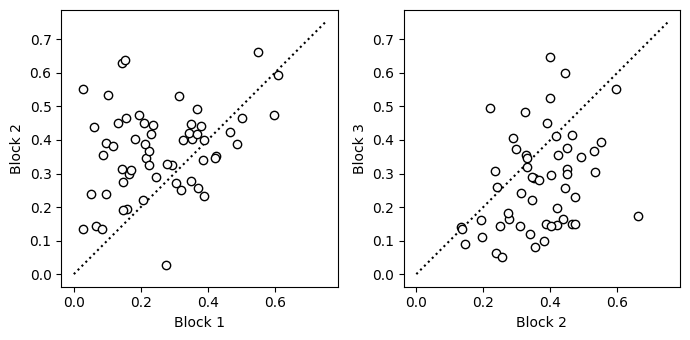

In [6]:
wt = (0.99, 0.99, 0.99)  # near-white marker fill

comparisons = [(0, 1, 1, 2), (1, 2, 2, 3)]  # (bi_x, bi_y, label_x, label_y)

fig, axs = plt.subplots(1, 2, figsize=(7, 3.5))

for ax, (bx, by, lx, ly) in zip(axs, comparisons):
    xs = bound_summary[:, bx, SNR_INDEX, 0, 0]  # mean bound, block lx
    ys = bound_summary[:, by, SNR_INDEX, 0, 0]  # mean bound, block ly

    valid = np.isfinite(xs) & np.isfinite(ys)

    # Identity line
    ax.plot([0, 0.75], [0, 0.75], 'k:')

    # One point per subject
    ax.plot(xs[valid], ys[valid], 'ko', markerfacecolor=wt)

    ax.set_xlabel(f'Block {lx}')
    ax.set_ylabel(f'Block {ly}')

    # Stats: median diff with IQR, Wilcoxon signed-rank, Spearman correlation
    diff = ys[valid] - xs[valid]
    pcts = np.percentile(diff, [25, 50, 75])
    _, p_rank = scipy.stats.wilcoxon(xs[valid], ys[valid])
    r, p_corr = scipy.stats.spearmanr(xs[valid], ys[valid])
    print(f'Block {lx} vs {ly}: median diff={pcts[1]:.2f} [{pcts[0]:.2f} {pcts[2]:.2f}], '
          f'p={p_rank:.3f}, Spearman r={r:.2f} (p={p_corr:.3f})')

    # RR correlation
    xrs = coin_summary[:, bx, SNR_INDEX][valid] / STEPS_PER_BLOCK_PD
    yrs = coin_summary[:, by, SNR_INDEX][valid] / STEPS_PER_BLOCK_PD
    rr, pr = scipy.stats.spearmanr(xrs, yrs)
    print(f'   RR: Spearman r={rr:.2f} (p={pr:.3f})')

plt.tight_layout()
plt.show()

## Within-block bound adaptation: methods

**Note on block numbering.** The top-row panels (A-C) above use `data_table_pd`, loaded
with the default `combine_snr=True`, which merges the raw 6-block PD task into 3 blocks
(raw blocks 4-6 are folded into 1-3). The tau/adaptation panels below (D-F) instead use a
separately loaded `data_table_pd_blocks = get_data_table(task_type='PD', combine_snr=False)`,
keeping the raw, unmerged 6-block numbering, so "Block 1/2/3" in the bottom row refers only
to each block's first raw exposure. This is necessary because within-block adaptation is
fit from trial 1 onward, and a combined "block" is actually two separate exposures
concatenated -- fitting a single from-trial-1 curve across that boundary would not be
meaningful.

For each subject x block, the code below computes a smoothed z-scored `abs_bound`
curve over the first 40 trials and tests whether it shows reliable time-locked
structure relative to a permutation null. The resulting curves and tau fits are
shown as the bottom row of the formatted figure. Unlike OL, PD subjects set the
bound directly each trial rather than having it estimated from behavior, so this
panel asks a distinct question: even with an explicit bound choice available every
trial, do subjects still show a systematic within-block trend in that choice (e.g.
converging toward a preferred bound as they learn the block's reward structure)?

**Smoothed z-scored curve.** `abs_bound` is z-scored per subject x block (so the
curve reflects within-block adaptation relative to that subject's own block-average
bound), then smoothed with a +/-3-trial sliding window. We also compute 1000
permutations of each subject's own trial order within the block -- preserving that
subject's noise level but destroying any time structure -- giving a null distribution
specific to each subject. The max-stat (Tmax, 95th percentile over all 40 trials)
of the group-mean null curves provides a multiple-comparison-corrected threshold.

**tau-fit eligibility.** Block 1 is gated by a within-block permutation test
(no preceding block). Blocks 2 and 3 are gated by a per-subject Mann-Whitney U
test on steady-state |bound| between block[i-1] and block[i] -- a subject can shift
reliably between blocks without that shift resolving as a clean within-block
exponential settle, so these criteria are kept separate. Fits that hit the `tau_max`
boundary are excluded from the tau summary (shown as open triangles in the figure)
since they represent a lower bound, not a measurement.

In [7]:
from pigeon.adaptation import (
    compute_per_subject_curves_with_nulls,
    per_subject_significance,
    group_null_band,
    between_block_significance,
    fit_exp_tau,
)

SUPP_MAX_TRIAL = 40
SUPP_BLOCKS    = [1, 2, 3]
SUPP_HALF_WIN  = 3
SUPP_MIN_WIN   = 3
N_PERM         = 1000
PERM_SEED      = 123
SIG_ALPHA      = 0.05
BETWEEN_MIN_TRIALS = 5  # min good trials per block required to run the between-block test

In [8]:
# Load PD data retaining all 6 raw blocks (combine_snr=False) for per-block analysis
data_table_pd_blocks = get_data_table(task_type='PD', combine_snr=False)

supp_trial_nums, supp_real, supp_perm, supp_subjects = compute_per_subject_curves_with_nulls(
    data_table_pd_blocks, SUPP_MAX_TRIAL, SUPP_BLOCKS,
    half_win=SUPP_HALF_WIN, min_win=SUPP_MIN_WIN, n_perm=N_PERM, seed=PERM_SEED)

# Group mean ± SEM for ribbon plots (all subjects, for display)
_n_valid       = np.sum(np.isfinite(supp_real), axis=0)
supp_mean      = np.nanmean(supp_real, axis=0)
supp_sem       = np.nanstd(supp_real, axis=0) / np.sqrt(np.maximum(_n_valid, 1))
supp_sem[_n_valid < 2] = np.nan

# Permutation-based group null band (max-stat corrected across the 40 trials) -- this
# and the within-block significance test below still describe the *within-block* curve
# shown in the top row, independent of which criterion gates the tau fits below.
supp_null_thresh = group_null_band(supp_perm, alpha=SIG_ALPHA)
supp_pvals, supp_sig = per_subject_significance(supp_real, supp_perm, alpha=SIG_ALPHA)

# Between-block significance: for blocks 2 and 3, does this subject's steady-state
# |bound| reliably differ from the immediately preceding block? (block 1 has no
# preceding block, so this is undefined there -- column 0 is all False/NaN.)
supp_between_pvals, supp_sig_between = between_block_significance(
    data_table_pd_blocks, SUPP_BLOCKS, alpha=SIG_ALPHA, min_trials=BETWEEN_MIN_TRIALS)

# Tau-fit eligibility: block 1 uses the within-block adaptation test (no alternative
# exists); blocks 2 and 3 use the between-block change test instead. supp_sig_between
# is computed independently with its own, looser trial-count filter, so it can flag a
# subject as eligible even if they have no finite curve point anywhere in the block
# (e.g. too few trials for compute_per_subject_curves_with_nulls' local window
# requirement) -- gate blocks 2/3 with has_curve so eligibility never outstrips the
# subjects that actually have a curve to fit (block 1 is already implicitly gated:
# per_subject_significance leaves pvals/sig as NaN/False wherever a subject has no
# curve data).
has_curve = np.any(np.isfinite(supp_real), axis=1)  # (n_subjects, n_blocks)
supp_sig_tau = supp_sig.copy()
supp_sig_tau[:, 1:] = supp_sig_between[:, 1:] & has_curve[:, 1:]

# Per-subject exponential fits -- only for subjects classified as eligible above.
# `censored` flags fits that hit tau_max: a real (eligible) deviation that isn't well
# described by a fast exponential settle within the 40-trial window (e.g. slow drift) --
# these are excluded from the tau summary/plot rather than silently padding it at the cap.
supp_taus     = np.full((len(supp_subjects), len(SUPP_BLOCKS)), np.nan)
supp_censored = np.zeros((len(supp_subjects), len(SUPP_BLOCKS)), dtype=bool)
for bi in range(len(SUPP_BLOCKS)):
    for si in range(len(supp_subjects)):
        if supp_sig_tau[si, bi]:
            tau, censored = fit_exp_tau(supp_trial_nums, supp_real[si, :, bi], tau_max=SUPP_MAX_TRIAL)
            supp_taus[si, bi]     = tau
            supp_censored[si, bi] = censored

print('Per-block adaptation summary:')
for bi, block in enumerate(SUPP_BLOCKS):
    n_total   = np.sum(np.any(np.isfinite(supp_real[:, :, bi]), axis=1))
    n_within  = np.sum(supp_sig[:, bi])
    mean_curve = supp_mean[:, bi]
    max_abs   = np.nanmax(np.abs(mean_curve))
    exceeds   = max_abs > supp_null_thresh[bi]
    print(f'  Block {block}: {n_within}/{n_total} subjects show within-block adaptation '
          f'({100 * n_within / max(n_total, 1):.0f}%)')
    print(f'    group mean curve: max|curve|={max_abs:.3f} vs. null threshold '
          f'±{supp_null_thresh[bi]:.3f} -> {"exceeds null" if exceeds else "within null"}')

    # n_qual = np.sum(supp_sig_tau[:, bi]), i.e. the actual eligibility mask used
    # for tau fitting below -- guaranteed <= n_total since supp_sig_tau is gated by
    # has_curve (see above).
    n_qual = np.sum(supp_sig_tau[:, bi])
    crit_label = ('within-block adaptation (no preceding block)' if bi == 0
                  else f'significant change vs. block {SUPP_BLOCKS[bi - 1]} (Mann-Whitney U)')
    print(f'    tau-fit eligibility: {n_qual}/{n_total} subjects qualify ({crit_label})')

    is_censored = supp_censored[:, bi]
    vt = supp_taus[:, bi][np.isfinite(supp_taus[:, bi]) & ~is_censored]
    n_cens = np.sum(is_censored)
    if len(vt):
        q25, med, q75 = np.percentile(vt, [25, 50, 75])
        print(f'    τ (eligible, non-censored): median={med:.1f}  '
              f'IQR=[{q25:.1f}, {q75:.1f}]  n={len(vt)}  '
              f'(+{n_cens} censored at tau_max, excluded)')
    else:
        print(f'    τ: no uncensored fits ({n_cens} eligible subjects censored at tau_max)')

Per-block adaptation summary:
  Block 1: 54/59 subjects show within-block adaptation (92%)
    group mean curve: max|curve|=0.777 vs. null threshold ±0.168 -> exceeds null
    tau-fit eligibility: 54/59 subjects qualify (within-block adaptation (no preceding block))
    τ (eligible, non-censored): median=6.2  IQR=[3.3, 11.6]  n=33  (+21 censored at tau_max, excluded)
  Block 2: 55/60 subjects show within-block adaptation (92%)
    group mean curve: max|curve|=1.555 vs. null threshold ±0.170 -> exceeds null
    tau-fit eligibility: 48/60 subjects qualify (significant change vs. block 1 (Mann-Whitney U))
    τ (eligible, non-censored): median=10.9  IQR=[6.9, 22.3]  n=34  (+14 censored at tau_max, excluded)
  Block 3: 45/54 subjects show within-block adaptation (83%)
    group mean curve: max|curve|=0.758 vs. null threshold ±0.177 -> exceeds null
    tau-fit eligibility: 41/54 subjects qualify (significant change vs. block 2 (Mann-Whitney U))
    τ (eligible, non-censored): median=7.9  IQ

## Formatted figure

Two-row x three-column figure saved to `Figure04S01.pdf`.

**Top row** (one panel per block): Scatter of mean bound (x) vs. reward rate (y) per
subject (error bars = SD of the bound set across trials). Light blue ribbon = 5th-95th
percentile of simulated reward rate vs. bound (1000 subjects per bound, fixed bound, PD's
800-step block budget via `BLOCK_DEFAULTS_PD`). The light blue vertical band marks the
near-optimal bounds (median simulated RR >= 95% of the curve's maximum); black dashed
crosshairs mark the participant median. Same conventions as `Figure04_RRvsBound.ipynb`.

**Bottom row** (one panel per block): Within-block z-scored bound adaptation curve with
permutation null band and a tau-fit inset, as described above.

Block 1: near-optimal bounds (>=95% of max median RR) 0.01-0.05
Block 2: near-optimal bounds (>=95% of max median RR) 0.43-0.65
Block 3: near-optimal bounds (>=95% of max median RR) 0.23-0.43


1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


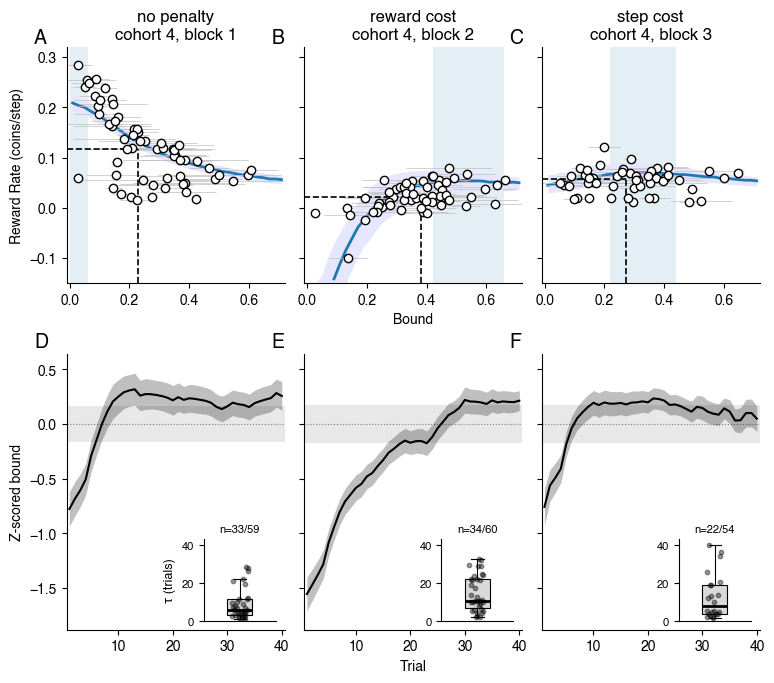

Saved /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Figures/Figure04S01.pdf (+ .png)

τ fits (eligible, non-censored):
  Block 1: median=6.2 [3.3, 11.6]  (n=33 good fits, 21 censored, 54 eligible)
  Block 2: median=10.9 [6.9, 22.3]  (n=34 good fits, 14 censored, 48 eligible)
  Block 3: median=7.9 [3.8, 19.2]  (n=22 good fits, 19 censored, 44 eligible)


In [9]:
import matplotlib.gridspec as gridspec

CM  = 1 / 2.54
WID = 17.6
HTS = [6.0, 7.0]
PSH = 1.8
PSW = 0.5
FS  = 12

fig_h       = sum(HTS) + PSH
panel_w     = (WID - 2 * PSW) / 3
hspace_frac = PSH / np.mean(HTS)
wspace_frac = PSW / panel_w

fig_comb = plt.figure(figsize=(WID * CM, fig_h * CM))
gs_comb  = gridspec.GridSpec(2, 3, figure=fig_comb,
                              height_ratios=HTS,
                              hspace=hspace_frac, wspace=wspace_frac,
                              left=0, right=1, bottom=0, top=1)
axs_top = [fig_comb.add_subplot(gs_comb[0, c]) for c in range(3)]
axs_bot = [fig_comb.add_subplot(gs_comb[1, c]) for c in range(3)]

plt.rcParams.update({'font.size': FS, 'axes.labelsize': FS, 'axes.titlesize': FS, **FONT_RC})

gr_c = (0.75, 0.75, 0.75)
wt_c = (0.99, 0.99, 0.99)
rp_c = (0.9,  0.9,  1.0)

# Color convention (consistent with Figure02c): blue = ideal/simulated benchmark,
# black = empirical participant data.
OPT_COLOR  = 'tab:blue'   # simulated RR curve and the peak of that curve
DATA_COLOR = 'k'          # median of the empirical data

# ── Pre-compute simulation ribbons for all blocks (single RNG pass) ───────────
# Done up-front so we can determine axis limits before drawing anything.
rng_comb = np.random.default_rng(0)
sbd_all = []
for bi, block in enumerate(BLOCKS):
    sbd = np.full((len(SIM_BOUNDS), 3), np.nan)
    for ss, bnd in enumerate(SIM_BOUNDS):
        sim_table = get_simulated_data_table(
            specs={'num_subjects': NUM_SIM_SUBJ, 'blocks': block},
            generative_mean=GENERATIVE_MEAN,
            bound_mean=bnd,
            rng=rng_comb,
            block_defaults=BLOCK_DEFAULTS_PD,
        )
        sim_coins = sim_table.groupby('subject_index')['coin_count'].last().to_numpy()
        sbd[ss] = np.percentile(sim_coins, [5, 50, 95]) / STEPS_PER_BLOCK_PD
    sbd_all.append(sbd)

# Axis limits (x extends left if the RR peak is at the smallest bound); y from just below the
# lowest participant reward rate, as in Figure04
all_opt_idx = [int(np.nanargmax(sbd[:, 1])) for sbd in sbd_all]
all_opt_x   = [float(SIM_BOUNDS[i]) for i in all_opt_idx]
all_opt_y   = [float(sbd_all[bi][all_opt_idx[bi], 1]) for bi in range(3)]
x_left      = min(0.0, min(all_opt_x) - 0.02)
y_top       = max(max(all_opt_y) * 1.08, 0.32)
TOP_XLIM    = (x_left, 0.72)
_rr_all     = coin_summary[:, :, SNR_INDEX] / STEPS_PER_BLOCK_PD
Y_FLOOR     = float(np.floor((np.nanmin(_rr_all) - 0.02) * 20) / 20)   # round down to 0.05
TOP_YLIM    = (Y_FLOOR, y_top)

# ── Top row: RR vs. bound ─────────────────────────────────────────────────────
# Ideal RR curve is blue, matching the "ideal observer" curve in Figure02c, as is the
# near-optimal band. The empirical data — participant scatter and its dashed median
# crosshair — are black.
for bi, block in enumerate(BLOCKS):
    ax  = axs_top[bi]
    sbd = sbd_all[bi]

    ax.fill_between(SIM_BOUNDS, np.maximum(sbd[:, 0], Y_FLOOR), np.maximum(sbd[:, 2], Y_FLOOR),
                    color=rp_c, linewidth=0)
    ax.plot(SIM_BOUNDS, np.where(sbd[:, 1] >= Y_FLOOR, sbd[:, 1], np.nan), '-', color=OPT_COLOR, linewidth=2)

    # Near-optimal bounds (median RR >= 95% of its maximum) as a blue band; no single optimum
    # is marked, since the curves are nearly flat near their peak.
    _near = SIM_BOUNDS[sbd[:, 1] >= 0.95 * np.nanmax(sbd[:, 1])]
    ax.axvspan(max(_near.min() - 0.01, TOP_XLIM[0]), _near.max() + 0.01, ymin=0, ymax=1,
               color=OPT_COLOR, alpha=0.12, lw=0, zorder=0)
    print(f'Block {block}: near-optimal bounds (>=95% of max median RR) {_near.min():.2f}-{_near.max():.2f}')

    # Data scatter: one point per subject, horizontal error bars = ±1 SD bound
    mean_b   = bound_summary[:, bi, SNR_INDEX, 0, 0]
    std_b    = bound_summary[:, bi, SNR_INDEX, 0, 1]
    rr       = coin_summary[:, bi, SNR_INDEX] / STEPS_PER_BLOCK_PD
    valid_bi = np.isfinite(mean_b) & np.isfinite(rr)

    ax.errorbar(mean_b[valid_bi], rr[valid_bi],
                xerr=std_b[valid_bi], fmt='none',
                ecolor=gr_c, elinewidth=0.5, capsize=0)
    ax.plot(mean_b[valid_bi], rr[valid_bi], 'ko', markerfacecolor=wt_c, zorder=4)

    # Black dashed crosshairs for the participant median
    med_x = float(np.nanmedian(mean_b[valid_bi]))
    med_y = float(np.nanmedian(rr[valid_bi]))
    ax.plot([med_x, med_x], [TOP_YLIM[0], med_y], '--', color=DATA_COLOR, lw=1.2, zorder=3)
    ax.plot([TOP_XLIM[0], med_x], [med_y, med_y], '--', color=DATA_COLOR, lw=1.2, zorder=3)

    ax.set_xlim(*TOP_XLIM)
    ax.set_ylim(*TOP_YLIM)
    if x_left < 0:
        ax.set_xticks([0, 0.2, 0.4, 0.6])   # hide the negative-margin tick
    ax.set_title(f'{CONDITION_LABELS[block]}\ncohort 4, block {block}')
    if bi == 1:
        ax.set_xlabel('Bound')
    if bi == 0:
        ax.set_ylabel('Reward Rate (coins/step)')
    else:
        ax.tick_params(axis='y', labelleft=False)
    for sp in ['top', 'right']:
        ax.spines[sp].set_visible(False)

# ── Bottom row: within-block learning curves with τ insets ───────────────────
# Curve + ribbon are black (empirical data), consistent with the top row's
# black data crosshairs. The permutation null band is a light gray, chosen to
# stay visually distinct from the black curve/ribbon (which render as a
# mid-gray at alpha=0.25) rather than blending into it.
_NULL_COLOR  = (0.85, 0.85, 0.85)
_CURVE_COLOR = 'k'

_top_lo  = min(np.nanmin(supp_mean - supp_sem), -np.max(supp_null_thresh))
_top_hi  = max(np.nanmax(supp_mean + supp_sem),  np.max(supp_null_thresh))
_top_pad = 0.08 * (_top_hi - _top_lo)
_CURVE_YLIM = (_top_lo - _top_pad, _top_hi + _top_pad)

_rng_jit = np.random.default_rng(42)

for bi, block in enumerate(SUPP_BLOCKS):
    ax = axs_bot[bi]
    mn  = supp_mean[:, bi]
    sem = supp_sem[:, bi]
    ok  = np.isfinite(mn) & np.isfinite(sem)
    thr = supp_null_thresh[bi]

    ax.axhline(0, color='k', linestyle=':', linewidth=0.8, zorder=0)
    ax.axhspan(-thr, thr, color=_NULL_COLOR, alpha=0.6, linewidth=0, zorder=0)
    ax.fill_between(supp_trial_nums[ok], mn[ok] - sem[ok], mn[ok] + sem[ok],
                    alpha=0.25, color=_CURVE_COLOR, linewidth=0)
    ax.plot(supp_trial_nums[ok], mn[ok], '-', color=_CURVE_COLOR, linewidth=1.5)

    ax.set_xlim(0.5, SUPP_MAX_TRIAL + 0.5)
    ax.set_ylim(*_CURVE_YLIM)
    if bi == 0:
        ax.set_ylabel('Z-scored bound')
    else:
        ax.tick_params(axis='y', labelleft=False)
    if bi == 1:
        ax.set_xlabel('Trial')
    for sp in ['top', 'right']:
        ax.spines[sp].set_visible(False)

    # ── τ inset (lower-right corner of the learning-curve panel) ──────────────
    ax_ins = ax.inset_axes([0.63, 0.03, 0.33, 0.30])

    is_cens = supp_censored[:, bi]
    vt      = supp_taus[:, bi][np.isfinite(supp_taus[:, bi]) & ~is_cens]
    n_total = int(np.sum(np.any(np.isfinite(supp_real[:, :, bi]), axis=1)))

    if len(vt):
        ax_ins.boxplot(vt, positions=[1], widths=0.35,
                       patch_artist=True,
                       medianprops=dict(color='k', linewidth=2),
                       boxprops=dict(facecolor=(0.85, 0.85, 0.85), linewidth=0.8),
                       whiskerprops=dict(linewidth=0.8),
                       capprops=dict(linewidth=0.8),
                       flierprops=dict(marker='none'))
        jit = _rng_jit.uniform(-0.12, 0.12, len(vt))
        ax_ins.scatter(np.ones(len(vt)) + jit, vt, s=10, color='k', alpha=0.4, zorder=4)
    else:
        ax_ins.text(1, SUPP_MAX_TRIAL / 2, 'no fits', ha='center', va='center',
                    fontsize=FS - 4)

    # n label above the inset: fit subjects (successful, non-censored) over the
    # total number of subjects with usable data in this block.
    ax_ins.text(0.5, 1.05, f'n={len(vt)}/{n_total}', transform=ax_ins.transAxes,
                ha='center', va='bottom', fontsize=FS - 4)

    ax_ins.set_xlim(0.5, 1.5)
    ax_ins.set_ylim(0, SUPP_MAX_TRIAL * 1.08)
    ax_ins.set_xticks([])
    if bi == 0:
        ax_ins.set_ylabel('τ (trials)', fontsize=FS - 3)
    ax_ins.tick_params(labelsize=FS - 4)
    for sp in ['top', 'right']:
        ax_ins.spines[sp].set_visible(False)

for bi in range(3):
    add_panel_label(axs_top[bi], chr(65 + bi))
    add_panel_label(axs_bot[bi], chr(68 + bi))

out_comb = FIGURES_DIR / 'Figure04S01.pdf'
fig_comb.savefig(out_comb, dpi=300, bbox_inches='tight')
fig_comb.savefig(out_comb.with_suffix('.png'), dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved {out_comb} (+ .png)')

# ── τ summary for manuscript reporting ───────────────────────────────────────
print('\nτ fits (eligible, non-censored):')
for bi, block in enumerate(SUPP_BLOCKS):
    is_cens = supp_censored[:, bi]
    vt      = supp_taus[:, bi][np.isfinite(supp_taus[:, bi]) & ~is_cens]
    n_cens  = int(np.sum(is_cens))
    n_qual  = (int(np.sum(supp_sig[:, bi])) if bi == 0
               else int(np.sum(supp_sig_between[:, bi])))
    if len(vt) >= 3:
        q25, med, q75 = np.percentile(vt, [25, 50, 75])
        print(f'  Block {block}: median={med:.1f} [{q25:.1f}, {q75:.1f}]  '
              f'(n={len(vt)} good fits, {n_cens} censored, {n_qual} eligible)')
    else:
        print(f'  Block {block}: insufficient fits  '
              f'(n={len(vt)} good, {n_cens} censored, {n_qual} eligible)')